# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [94]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary
# Any other imports you need

## Binary classification


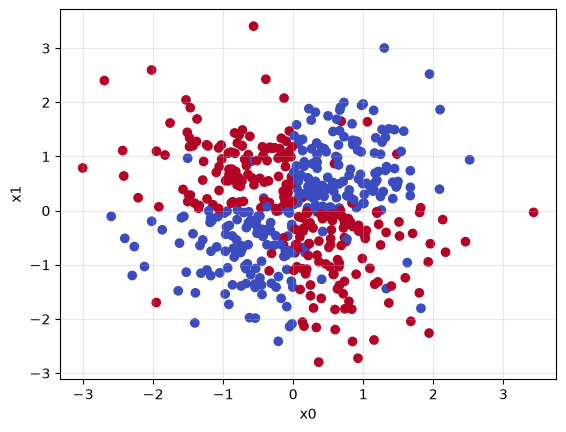

In [95]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()

Test accuracy: 0.910 (krav: >= 0.90), epoker kjørt: 201
Parametre: 1185


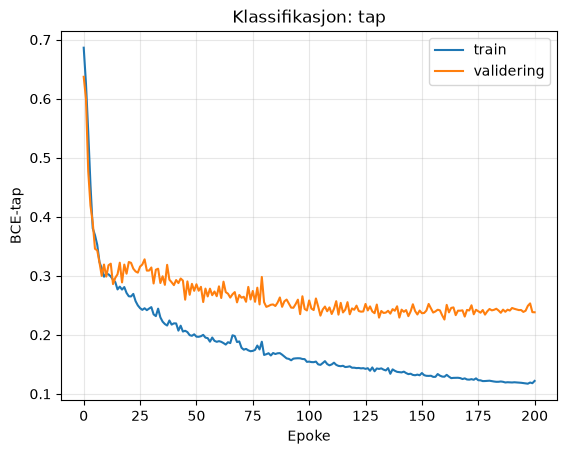

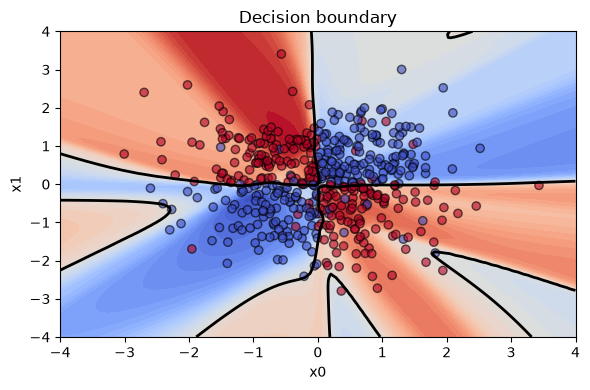

In [96]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

import random
import torch
import torch.nn as nn

# Fast seed for like resultater
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()

def split_train_val(X, y, frac=0.2):
    # Deler treningsdata i trening og validering
    idx = np.random.RandomState(SEED).permutation(len(X))
    n_val = int(frac * len(X))
    v, t = idx[:n_val], idx[n_val:]
    return X[t], y[t], X[v], y[v]


def fit(model, loss_fn, X_tr, y_tr, X_val, y_val, epochs=300, batch=32, lr=1e-2, patience=40, wd=0.0):
    # Trener modellen og lagrer trenings- og valideringstap.
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)  # Senker læringsraten underveis
    gen = torch.Generator().manual_seed(SEED)                      # Fast seed for batch-rekkefølgen
    best, best_state, bad = float("inf"), None, 0
    tr_hist, val_hist = [], []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr), generator=gen)           # Blander dataene hver epoke
        total = 0.0
        for i in range(0, len(X_tr), batch):                       # Trener på én batch om gangen
            b = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(X_tr[b]), y_tr[b])
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        sched.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(X_val), y_val).item()
        tr_hist.append(total / len(X_tr))
        val_hist.append(v)
        if v < best:                                               # Lagrer vektene hvis valideringstapet blir lavere
            best, bad = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)                              # Henter de beste vektene
    return tr_hist, val_hist

# Deler treningsdata og setter testdata til side
clf_train = data[data["split"] == "train"]
clf_test = data[data["split"] == "test"]
Xa = clf_train[["x0", "x1"]].values.astype("float32")
ya = clf_train["y"].values.astype("float32")
Xtr, ytr, Xva, yva = [torch.tensor(a) for a in split_train_val(Xa, ya)]
Xte = torch.tensor(clf_test[["x0", "x1"]].values, dtype=torch.float32)
yte = torch.tensor(clf_test["y"].values, dtype=torch.float32)

# To skjulte lag med 32 nevroner og tanh
class Squeeze(nn.Module):
    def forward(self, x):
        return x.squeeze(1)

clf_model = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1), Squeeze(),          # Utgangen er en logit
)
bce = nn.BCEWithLogitsLoss()               # BCE med innebygd sigmoid

set_seed()
clf_tr_loss, clf_val_loss = fit(clf_model, bce, Xtr, ytr, Xva, yva)

# Tester modellen
clf_model.eval()
with torch.no_grad():
    acc = ((clf_model(Xte) > 0).float() == yte).float().mean().item()
print(f"Test accuracy: {acc:.3f} (krav: >= 0.90), epoker kjørt: {len(clf_tr_loss)}")
print("Parametre:", sum(p.numel() for p in clf_model.parameters()))

# Plotter trenings- og valideringstap
plt.plot(clf_tr_loss, label="train")
plt.plot(clf_val_loss, label="validering")
plt.xlabel("Epoke"); plt.ylabel("BCE-tap"); plt.title("Klassifikasjon: tap")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Plotter beslutningsgrensen med terskel 0
def clf_predict(pts):
    with torch.no_grad():
        return clf_model(torch.tensor(pts, dtype=torch.float32)).numpy()

plot_decision_boundary(clf_predict, points=Xte.numpy(), labels=yte.numpy(), threshold=0.0)
plt.show()

### ❓ Visualize the network architecture for both classification and regression.

Klassifikasjonsmodellen tar inn x0 og x1. Den har to skjulte lag med 32 nevroner i hvert lag. Begge bruker tanh som aktiveringsfunksjon. Dette gjør at modellen kan lære et mønster som ikke kan skilles med en rett linje. Det siste laget gir én verdi, kalt en logit. Er verdien større enn null, velger vi klasse 1. Ellers velger vi klasse 0. Sigmoid er inkludert i tapsfunksjonen BCEWithLogitsLoss. Modellen har 1185 parametere som læres under trening.

Regresjonsmodellen tar også inn x0 og x1. Den har to skjulte lag med 64 nevroner i hvert lag og bruker GELU som aktiveringsfunksjon. Det siste laget gir én tallverdi som er prediksjonen av y. Her brukes ingen aktiveringsfunksjon etter siste lag, siden svaret skal være en kontinuerlig verdi. Vi skalerer y før trening og gjør prediksjonene om til den opprinnelige skalaen etterpå. Modellen har 4417 parametere.

### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values?

Beslutningsgrensen viser hvor modellen skiller mellom klassene. Innenfor treningsområdet følger den XOR-mønsteret godt. Klassen avhenger av om x0 og x1 har samme eller motsatt fortegn. Modellen får omtrent 91 prosent riktige svar på testdataene.

Treningsdataene har verdier mellom minus 2 og 2 for begge variablene. Vi kan derfor ikke regne med like gode svar for større verdier. Utenfor dette området må modellen gjøre prediksjoner uten å ha sett lignende data. Den har lært fra eksempler, men har ingen innebygd regel som sikrer at XOR-mønsteret fortsetter riktig utenfor treningsområdet.

## Regression


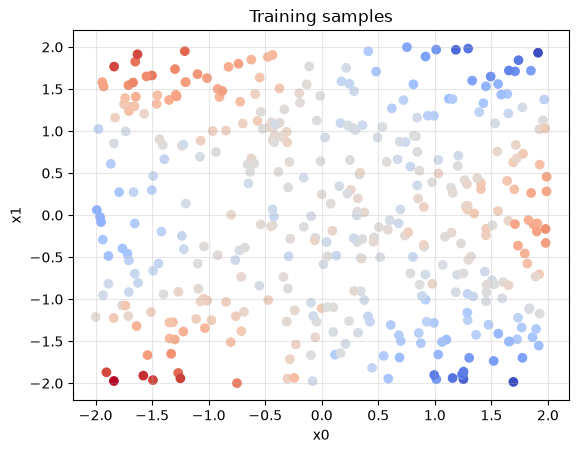

In [97]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

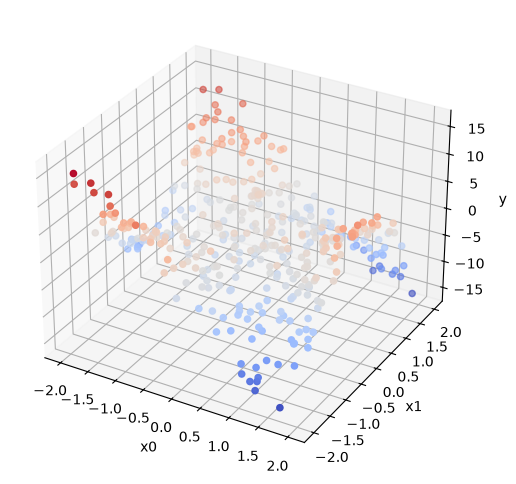

In [98]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

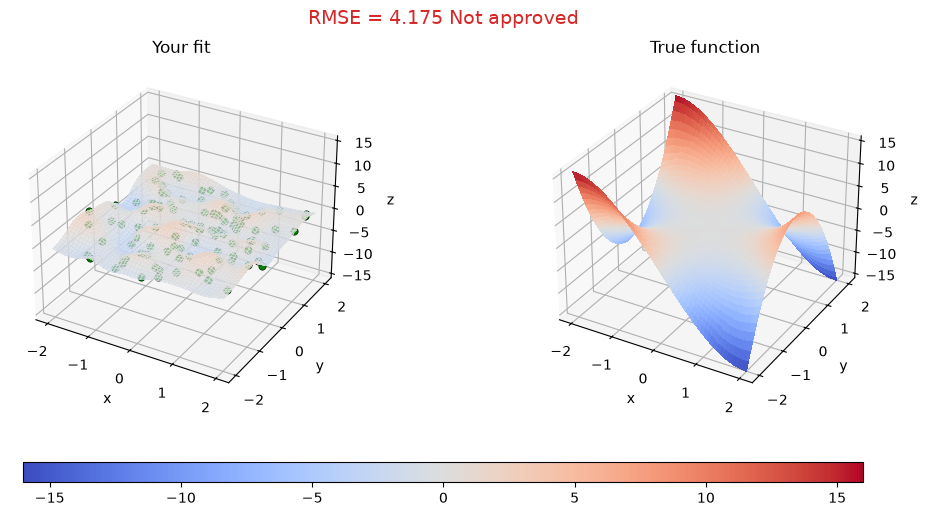

In [99]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))
plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

Parametre: 4417
Test RMSE: 0.232 (krav: <= 0.25), epoker kjørt: 204


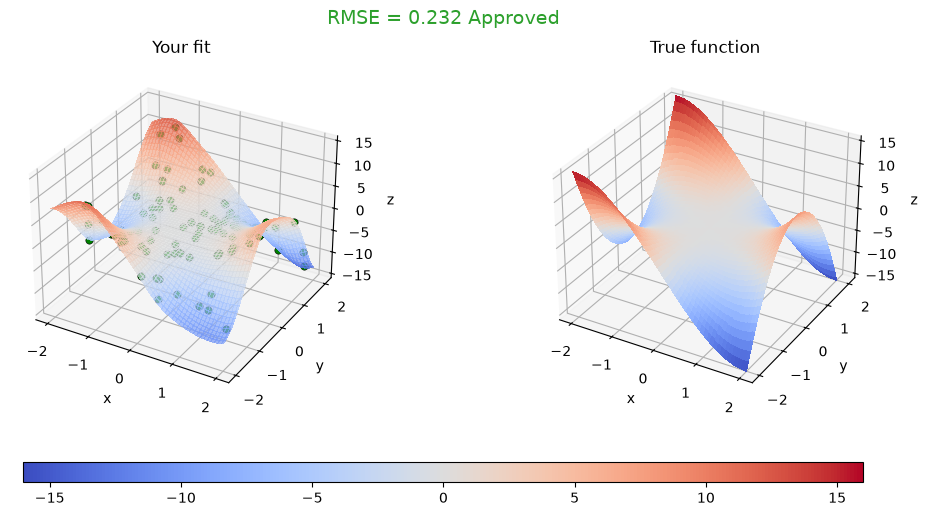

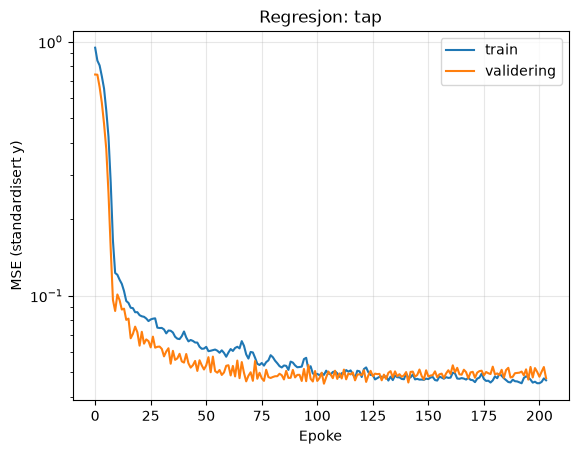

In [100]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

# Bruker funksjonene fra klassifikasjonen
# Skalerer y og bruker 20 % av treningsdataene til validering
reg_train = data[data["split"] == "train"]
reg_test = data[data["split"] == "test"]
Xa = reg_train[["x0", "x1"]].values.astype("float32")
ya = reg_train["y"].values.astype("float32")
y_mu, y_sd = ya.mean(), ya.std()
Xtr, ytr, Xva, yva = split_train_val(Xa, (ya - y_mu) / y_sd)
Xtr, ytr, Xva, yva = [torch.tensor(a) for a in (Xtr, ytr, Xva, yva)]
Xte_reg = torch.tensor(reg_test[["x0", "x1"]].values, dtype=torch.float32)

set_seed()

# To skjulte lag med 64 nevroner og GELU
reg_model = nn.Sequential(
    nn.Linear(2, 64), nn.GELU(),
    nn.Linear(64, 64), nn.GELU(),
    nn.Linear(64, 1), Squeeze(),
)

reg_tr_loss, reg_val_loss = fit(reg_model, nn.MSELoss(), Xtr, ytr, Xva, yva,
                                epochs=500, batch=64, lr=3e-3, patience=100, wd=1e-2)  # Weight decay for å redusere overtilpasning

# Predikerer på testdata og skalerer tilbake y
reg_model.eval()
with torch.no_grad():
    y_pred = reg_model(Xte_reg).numpy() * y_sd + y_mu
print("Parametre:", sum(p.numel() for p in reg_model.parameters()))
fig, _, rmse = plot_complex_fit(Xte_reg.numpy(), y_pred)   # Måler feilen mot den sanne funksjonen
print(f"Test RMSE: {rmse:.3f} (krav: <= 0.25), epoker kjørt: {len(reg_tr_loss)}")
plt.show()

# Plotter trenings- og valideringstap med log-skala
plt.plot(reg_tr_loss, label="train")
plt.plot(reg_val_loss, label="validering")
plt.yscale("log"); plt.xlabel("Epoke"); plt.ylabel("MSE (standardisert y)")
plt.title("Regresjon: tap"); plt.legend(); plt.grid(alpha=0.3); plt.show()


### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?

For klassifikasjon er treningstapet omtrent 0,12 og valideringstapet omtrent 0,23. Lavere tap betyr at prediksjonene passer bedre med svarene i datasettet. Modellen passer altså bedre på treningsdataene enn på valideringsdataene. Hvis treningstapet fortsetter å synke uten at valideringstapet blir bedre, kan det være et tegn på overtilpasning. Da lærer modellen også støy og detaljer som ikke hjelper på nye data. Early stopping beholder vektene fra epoken med lavest valideringstap.

For regresjon ligger treningstapet og valideringstapet nær hverandre, rundt 0,046 og 0,045. Begge kurvene flater ut. Det tyder på at modellen fungerer omtrent like godt på valideringsdataene som på treningsdataene, uten tydelige tegn til stor overtilpasning. Støy i y kan være en grunn til at tapet ikke blir lavere.

De siste tapsverdiene er nyttige, men er ikke nok alene. Vi bør også se på utviklingen i kurvene og resultatene på testdata. For klassifikasjon bruker vi andelen riktige svar. For regresjon bruker vi RMSE fra plot_complex_fit, som sammenligner prediksjonene med den sanne funksjonen uten støy. Dette kan ikke sammenlignes direkte med treningstapet, fordi treningstapet bruker skalerte y-verdier med støy. Testdata gir en mer uavhengig vurdering hvis de ikke brukes til å velge modell eller innstillinger.


### ❓ Which optimization techniques did you try? What worked and what did not?

Vi brukte AdamW til å oppdatere modellens vekter. Vi trente på små grupper med data om gangen, kalt mini-batcher, og senket læringsraten gradvis med cosine annealing. Vi brukte også early stopping, som stopper treningen når valideringstapet ikke blir bedre og henter tilbake de beste vektene. For regresjon brukte vi weight decay for å redusere overtilpasning.

For klassifikasjon fungerte tanh bedre enn ReLU i forsøkene. Tanh ga omtrent 90 til 91 prosent riktige svar, mens ReLU ga omtrent 89 til 90 prosent. Et større nettverk ga ikke bedre testresultater.

For regresjon fungerte GELU bedre enn tanh i forsøkene. Det beste oppsettet hadde to skjulte lag med 64 nevroner, batch-størrelse 64 og weight decay på 0,01. Dette ga RMSE mellom 0,21 og 0,25. Mindre batcher ga mer variasjon under treningen. Et tredje skjult lag ga også mer ustabile resultater og hjalp ikke.

Cosine annealing og early stopping ble brukt gjennom forsøkene, men ble ikke testet hver for seg. Vi kan derfor ikke si sikkert hvor mye hver av dem bidro.



### ❓ How did you ensure reproducibility?

Vi bruker en fast seed på 42 for random, NumPy og PyTorch. En seed er et startpunkt for de tilfeldige tallene som brukes i koden. Dette bidrar til like resultater når hele notebooken kjøres på nytt i samme miljø og i samme rekkefølge.

Vi bruker også en fast seed når dataene deles i trening og validering. Dermed havner de samme radene i hver del hver gang. Rekkefølgen på batchene styres av en egen generator med fast seed. Treningen kjøres på CPU.

Den første seed-innstillingen skjer før klassifikasjonsmodellen lages. Kallet rett før trening endrer ikke vektene som allerede er laget. Derfor er det viktig å kjøre cellene fra starten i samme rekkefølge. Å kjøre bare én treningscelle på nytt er ikke nødvendigvis nok til å få samme resultat.


# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [101]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

/var/folders/8x/j91qbcqj2pb_nbypg1wvplvh0000gn/T/ipykernel_18639/3436741196.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data = data.reset_index(names="ID")


,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [102]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


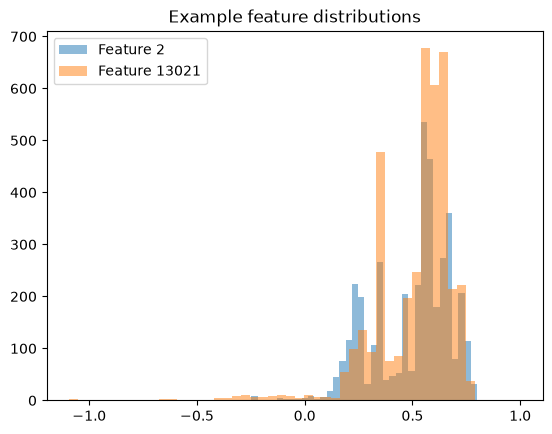

In [103]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

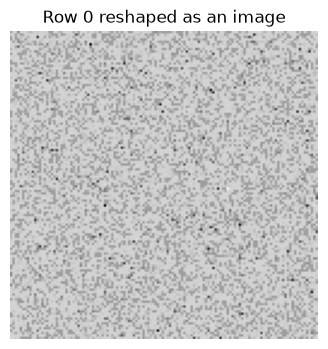

In [104]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [105]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


Bilder: (4000, 128, 128)


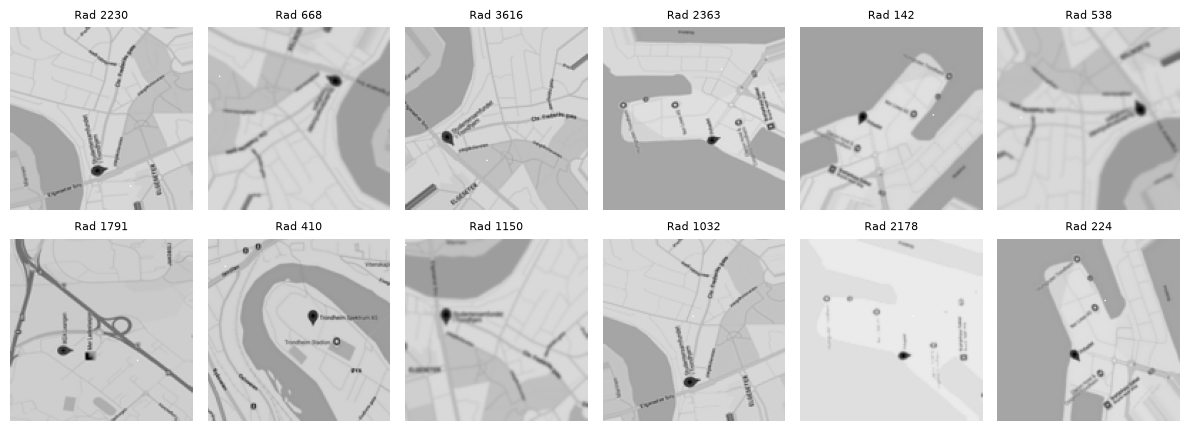

In [106]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

#YOUR CODE GOES HERE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Første rad hadde kolonnenavn som col_N, der N er pikselnummeret
header = pd.read_csv("unsupervised_data.csv", nrows=0).columns
order = np.array([int(c.split("_")[1]) for c in header])

# Setter hver kolonne på riktig plass og lager bilder på 128x128
X = data.drop(columns="ID").to_numpy(dtype="float32")
images = np.empty_like(X)
images[:, order] = X
del X
images = images.reshape(-1, 128, 128)
flat = images.reshape(len(images), -1)
print("Bilder:", images.shape)

# Viser 12 tilfeldige bilder etter sorteringen
rng = np.random.RandomState(0)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.ravel(), rng.choice(len(images), 12, replace=False)):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Rad {i}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


Forklart varians, 50 komponenter: 0.655


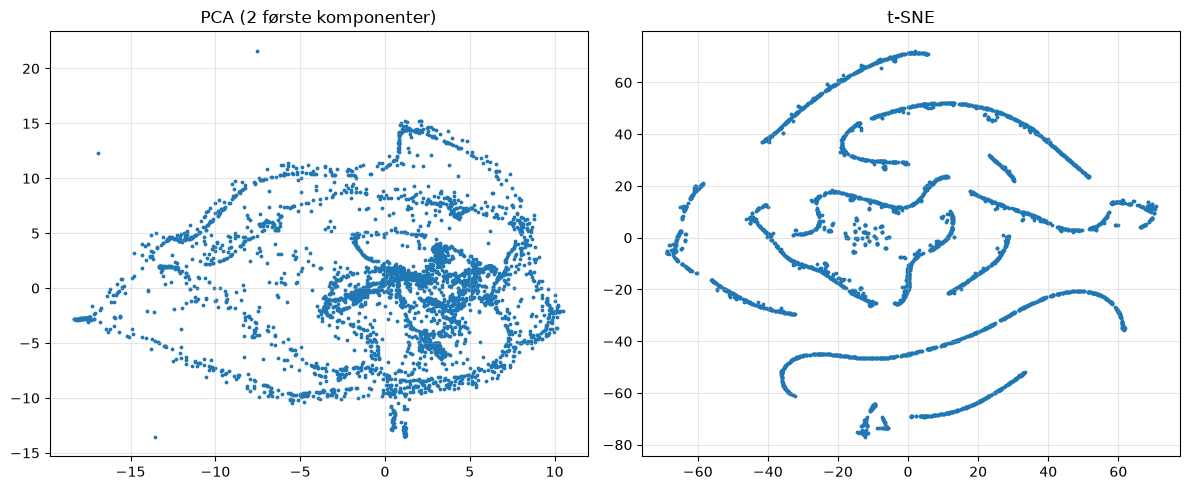

In [107]:
# PCA til 50 komponenter. Resten av analysen bruker disse
pca = PCA(n_components=50, svd_solver="randomized", random_state=42)
Z = pca.fit_transform(flat)
print("Forklart varians, 50 komponenter:", round(pca.explained_variance_ratio_.sum(), 3))

# t-SNE kjøres bare på de 50 komponentene, med én tråd, for å spare minne og CPU
tsne_xy = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=1).fit_transform(Z)

# Sammenligner PCA og t-SNE i 2D
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(Z[:, 0], Z[:, 1], s=3)
axes[0].set_title("PCA (2 første komponenter)")
axes[1].scatter(tsne_xy[:, 0], tsne_xy[:, 1], s=3)
axes[1].set_title("t-SNE")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [108]:
# KMeans med ulike k. Silhouette gir ingen tydelig topp
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(Z)
    print(f"k={k}: silhouette={silhouette_score(Z, km.labels_):.3f}")

# DBSCAN på PCA-dataene. min_samples=2 gjør at bare enkeltbilder blir støy
for eps in (6, 8, 10, 11, 11.6, 12.2, 12.5, 14):
    lab = DBSCAN(eps=eps, min_samples=2).fit_predict(Z)
    sizes = sorted(np.bincount(lab[lab >= 0]).tolist(), reverse=True)
    print(f"eps={eps}: {len(sizes)} klynger, {(lab < 0).sum()} støy, største: {sizes[:5]}")

k=2: silhouette=0.092
k=3: silhouette=0.087
k=4: silhouette=0.105
k=5: silhouette=0.121
k=6: silhouette=0.140
k=7: silhouette=0.148
k=8: silhouette=0.178
eps=6: 47 klynger, 48 støy, største: [999, 973, 934, 928, 8]
eps=8: 19 klynger, 13 støy, største: [999, 989, 986, 962, 8]
eps=10: 9 klynger, 4 støy, største: [999, 999, 995, 980, 8]
eps=11: 4 klynger, 4 støy, største: [999, 999, 999, 999]
eps=11.6: 4 klynger, 4 støy, største: [999, 999, 999, 999]
eps=12.2: 4 klynger, 4 støy, største: [999, 999, 999, 999]
eps=12.5: 2 klynger, 4 støy, største: [2997, 999]
eps=14: 1 klynger, 3 støy, største: [3997]


Antall klynger: 4
Størrelser: [999, 999, 999, 999]
Rader som ikke hører til: [181, 968, 2117, 2251]
ARI KMeans mot DBSCAN: 0.376
Klyngenavn: {np.int64(3): 'Pirbadet', np.int64(2): 'Studentersamfundet', np.int64(0): 'Trondheim Spektrum', np.int64(1): 'IKEA Leangen'}


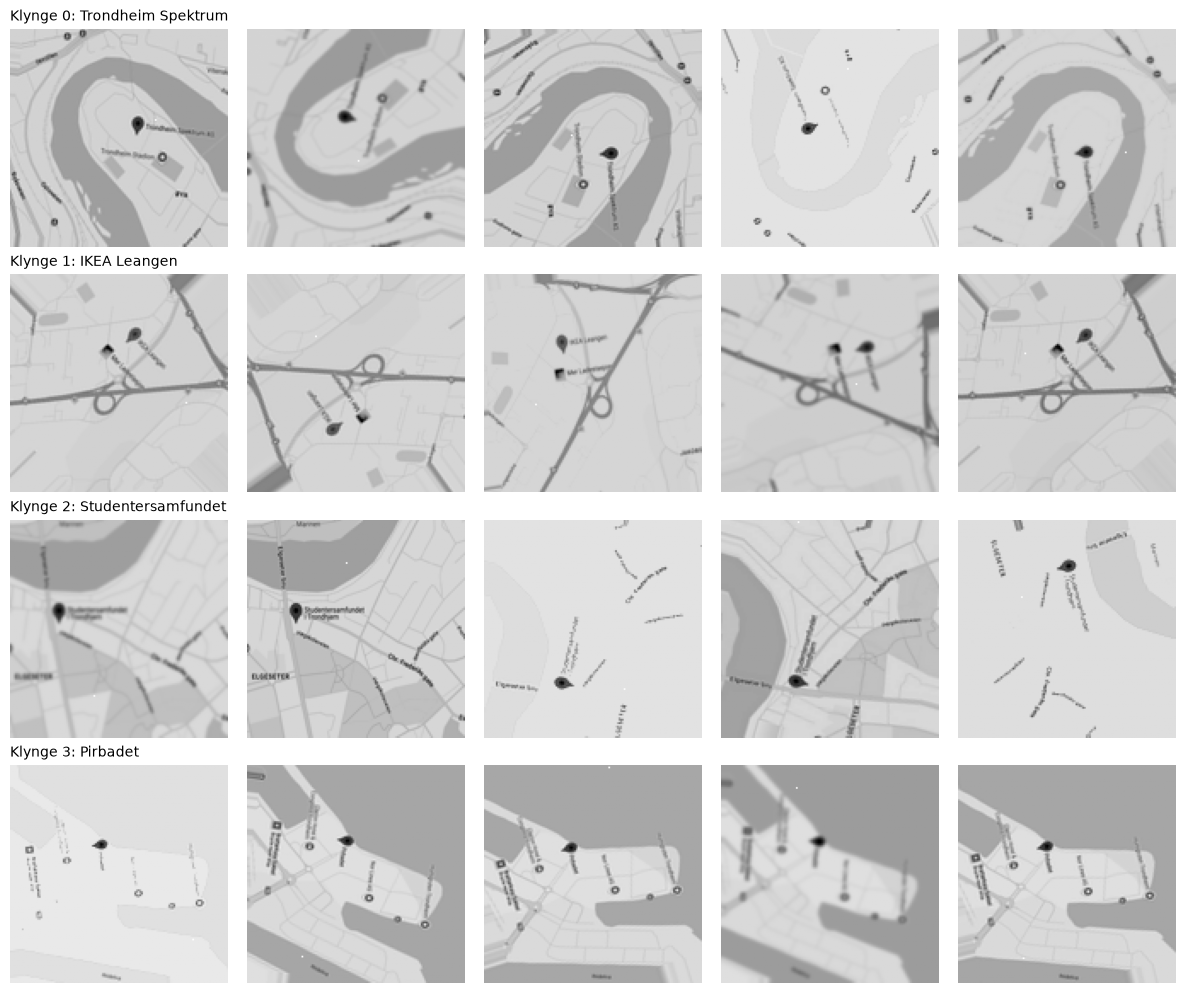

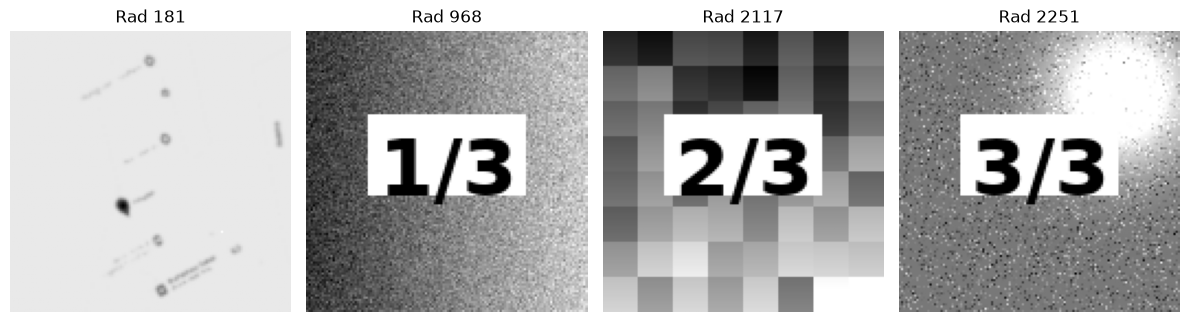

In [109]:
# Endelig klynging: eps=11.6 ligger midt i området (11 til 12.2) som gir fire klynger
db = DBSCAN(eps=11.6, min_samples=2).fit(Z)
labels = db.labels_
noise = np.where(labels == -1)[0]
print("Antall klynger:", len(set(labels) - {-1}))
print("Størrelser:", np.bincount(labels[labels >= 0]).tolist())
print("Rader som ikke hører til:", noise.tolist())

# KMeans med k=4 for sammenligning. ARI = 1 betyr lik gruppering
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Z)
print("ARI KMeans mot DBSCAN:", round(adjusted_rand_score(labels[labels >= 0], km4[labels >= 0]), 3))

# Navn på stedene ble lest av kartene. Vi bruker én kjent rad for hvert sted
examples = {"Pirbadet": 391, "Studentersamfundet": 664, "Trondheim Spektrum": 1429, "IKEA Leangen": 1206}
place = {labels[i]: name for name, i in examples.items()}
print("Klyngenavn:", place)

# Viser 5 tilfeldige bilder fra hver klynge
rng = np.random.RandomState(3)
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for r, k in enumerate(sorted(place)):
    for c, i in enumerate(rng.choice(np.where(labels == k)[0], 5, replace=False)):
        axes[r, c].imshow(images[i], cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(f"Klynge {k}: {place[k]}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

# Viser radene DBSCAN regnet som støy
fig, axes = plt.subplots(1, len(noise), figsize=(12, 3.4))
for ax, i in zip(axes, noise):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Rad {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [110]:
# Støyrader får nærmeste klynge (nærmeste sentroide) i submission
final = labels.copy()
centroids = np.array([Z[labels == k].mean(axis=0) for k in range(4)])
for i in noise:
    final[i] = np.argmin(np.linalg.norm(centroids - Z[i], axis=1))

submission = pd.DataFrame({"ID": data["ID"], "cluster": final})
submission.to_csv("submission.csv", index=False)
print(submission.shape, submission["cluster"].value_counts().sort_index().to_dict())
submission.head()

(4000, 2) {0: 999, 1: 999, 2: 1000, 3: 1002}


,ID,cluster
0,0,0
1,1,1
2,2,0
3,3,1
4,4,2


### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.

Vi startet med PCA til 50 komponenter, som beholder omtrent 65 prosent av variansen. I 2D med de to første PCA-komponentene ligger nesten alle punktene i én stor sky uten tydelige grupper. t-SNE viser derimot lange, krumme striper som er tydelig adskilt. PCA er lineær og bevarer de store retningene i dataene. t-SNE bevarer nærheten mellom naboer bedre, og viser derfor lokal struktur som PCA skjuler. Avstandene mellom stripene i t-SNE sier derimot lite, så vi brukte ikke t-SNE-plottet til å telle klynger direkte.

Silhouette-scoren for KMeans steg jevnt fra k=2 til k=8 uten en tydelig topp, så den hjalp ikke oss å velge k. t-SNE viste mange striper, fordi samme sted er tatt med ulik zoom og forskyvning. Antall klynger fant vi med DBSCAN på PCA-dataene. For eps mellom 11 og 12,2 får vi akkurat fire klynger på 999 bilder hver og fire rader som støy. Det blir 4 · 999 + 4 = 4000. Bildene viser også fire ulike steder. Vi velger derfor k = 4.

### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.

Vi brukte DBSCAN med eps=11,6 og min_samples=2 på de 50 PCA-komponentene. Med min_samples=2 blir bare bilder uten noen nær nabo regnet som støy. Eps ligger midt i området 11 til 12,2 som gir fire klynger. Under 11 deles stedene i flere deler, og ved 12,5 smelter tre av stedene sammen. Valget er altså følsomt for eps, og vi har ikke fasit lokalt. Nøyaktigheten på 99 prosent må derfor sjekkes på Kaggle med submission.csv.

KMeans med k=4 passet dårlig. Justert Rand-indeks mot DBSCAN er bare omtrent 0,38. Hvert sted finnes i mange zoomnivåer og posisjoner, så klyngene er lange kjeder av bilder som glir over i hverandre. De er ikke runde klumper. KMeans deler rommet i like store runde områder og skjærer derfor gjennom stedene. DBSCAN følger kjeden av nære naboer og får dem riktig. Ulempen med DBSCAN er at den trenger riktig eps og kan slå sammen steder hvis eps blir for stor.

### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?

Den skjulte modaliteten er bilder. Første rad i filen hadde kolonnenavn som col_N, der N er pikselnummeret i et bilde på 128 × 128 gråtoner. Pikslene lå i tilfeldig rekkefølge. Når vi setter hver kolonne på plassen N, får vi kartutsnitt fra Trondheim med en nål som markerer et sted.

Rekkefølgen på kolonnene har ingen betydning for PCA, KMeans eller DBSCAN, siden avstandene mellom radene blir like selv om alle kolonner byttes om på samme måte. Sorteringen var derfor nødvendig for å se bildene, ikke for å få klyngene. Vi trengte den for å forstå hva klyngene var, lese stedsnavn og finne radene som ikke hører til. Bildedata har mange dimensjoner (16384), så PCA først gjør alt senere raskere. Zoom og forskyvning gjør at samme sted får mange ulike pikselmønstre, og det er derfor klyngene blir kjeder.

### ❓ List the facilities in Trondheim and how you identified them.

Vi fant fire steder ved å se på bildene fra hver klynge og lese stedsnavnene på kartene:

- **Pirbadet** (klynge 3): bilder av en halvøy med havn. Nålen står ved Pirbadet. Dette er sikkert.
- **Studentersamfundet i Trondhjem** (klynge 2): bymiljø ved Nidelva med Elgeseter gate og Chr. Fredriks gate. Navnet kan leses på kartene.
- **Trondheim Spektrum** (klynge 0): en tydelig elvesving med Trondheim Spektrum og Trondheim stadion.
- **IKEA Leangen** (klynge 1): et veikryss med sløyfe ved E6. Teksten er veldig liten, så vi er mindre sikre på dette navnet enn på de andre.

Klyngenumrene kommer fra DBSCAN og skrives ut i koden over.

### ❓ How did you detect the rows that do not belong, and what were they?

DBSCAN markerte fire rader som støy, fordi ingen andre bilder ligger nær dem:

- **Rad 968, 2117 og 2251** er ikke kart. De er bilder med støy eller gradient og teksten «1/3», «2/3» og «3/3».
- **Rad 181** er et kart, men nesten blankt og utvasket, zoomet langt ut med få detaljer. Avstanden til nærmeste nabo er omtrent 13,8 i PCA-rommet, mot omtrent 0,7 for en typisk rad. Den ligner mest på Pirbadet-bildene når de er zoomet langt ut.

Vi satte alle fire inn i nærmeste klynge i submission.csv. De er bare fire av 4000 rader, så det har liten betydning for nøyaktigheten.

---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [111]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [112]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [113]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [114]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)